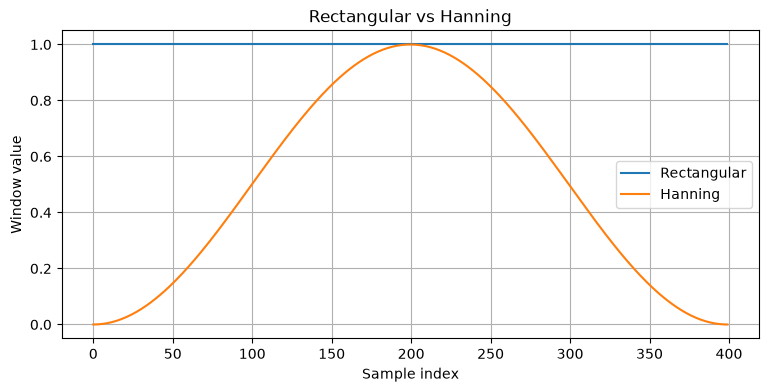

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

#实验1：观察两种窗函数
sr = 16000
win_length = 400

rect_win = np.ones(win_length)

hann_win = np.hanning(win_length)

n = np.arange(win_length)

plt.figure(figsize=(9,4))
plt.plot(n,rect_win,label="Rectangular")
plt.plot(n,hann_win,label="Hanning")

plt.xlabel("Sample index")
plt.ylabel("Window value")
plt.title("Rectangular vs Hanning")
plt.legend()
plt.grid(True)
plt.show()

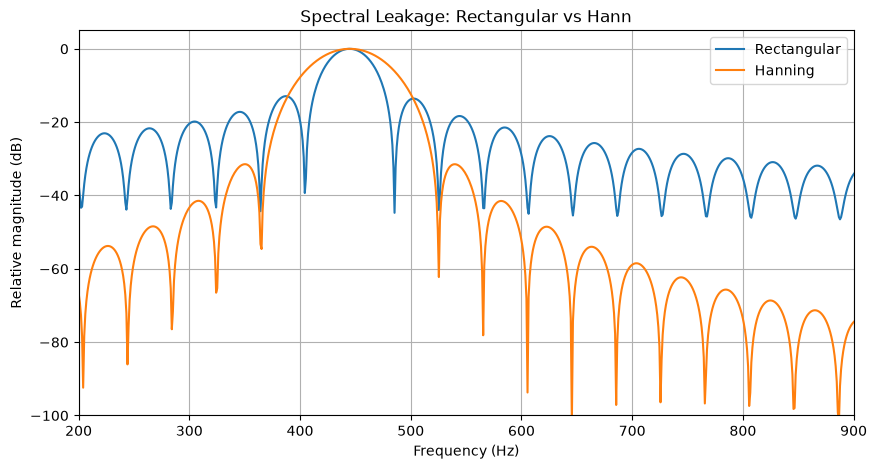

In [2]:
#实验2：使用纯音比较频谱泄露
f = 445
sr = 16000
win_length = 400
n_fft = 16384

t = np.arange(win_length) / sr

x = np.sin(2*np.pi*f*t)

#两种加窗方式
x_rect = x * np.ones(win_length)
x_hann = x * np.hanning(win_length)

#补零后计算rFFT
X_rect = np.fft.rfft(x_rect,n=n_fft)
X_hann = np.fft.rfft(x_hann,n=n_fft)

freqs = np.fft.rfftfreq(n_fft, 1/sr)

mag_rect = np.abs(X_rect)
mag_hann = np.abs(X_hann)

#归一化
mag_rect_norm = mag_rect / (mag_rect.max() + 1e-12)
mag_hann_norm = mag_hann / (mag_hann.max() + 1e-12)

#转为dB
db_rect = 20 * np.log10(mag_rect_norm + 1e-12)
db_hann = 20 * np.log10(mag_hann_norm + 1e-12)

plt.figure(figsize=(10,5))

plt.plot(freqs,db_rect,label="Rectangular")
plt.plot(freqs,db_hann,label="Hanning")

plt.xlim(200,900)
plt.ylim(-100,5)

plt.xlabel("Frequency (Hz)")
plt.ylabel("Relative magnitude (dB)")
plt.title("Spectral Leakage: Rectangular vs Hann")
plt.legend()
plt.grid(True)
plt.show()

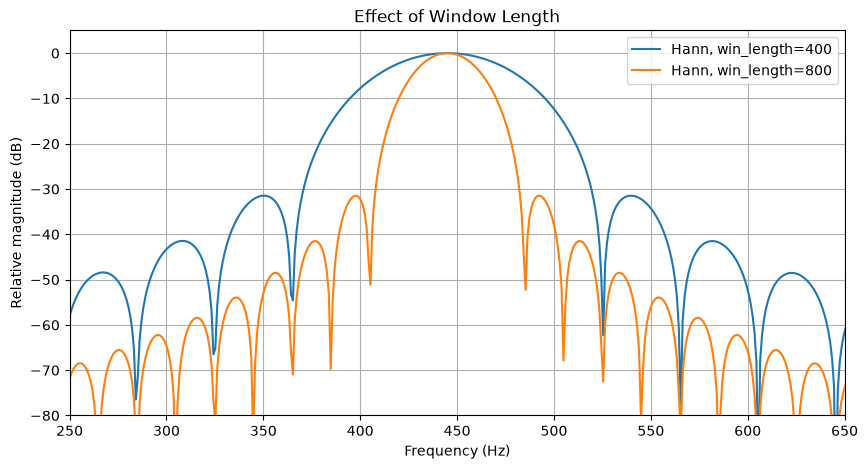

In [3]:
#实验3：改变窗长，观察主瓣宽度
sr = 16000
f = 445
n_fft = 16384

plt.figure(figsize=(10,5))

for win_length in [400,800]:
    t = np.arange(win_length) / sr

    x = np.sin(2*np.pi*f*t)
    win = np.hanning(win_length)

    X = np.fft.rfft(x * win, n=n_fft)

    freqs = np.fft.rfftfreq(n_fft, d=1/sr)

    mag = np.abs(X)
    mag = mag / (mag.max() + 1e-12)

    db = 20 * np.log10(mag + 1e-12)

    plt.plot(
        freqs,
        db,
        label=f"Hann, win_length={win_length}"
    )

plt.xlim(250,650)
plt.ylim(-80,5)
plt.xlabel("Frequency (Hz)")
plt.ylabel("Relative magnitude (dB)")
plt.title("Effect of Window Length")
plt.legend()
plt.grid(True)
plt.show()

In [2]:
#实验4：STFT矩阵形状推导
import numpy as np
import librosa

sr = 16000
N = 16000

win_length = 400
hop_length = 160
n_fft = 512

#1s测试信号
t = np.arange(N) / sr
x = np.sin(2*np.pi*440*t)

#理论频点数
F = n_fft // 2 + 1

# center = False
T_false = 1 + (N - n_fft) // hop_length

#center = True
T_true = 1 + N // hop_length

D_false = librosa.stft(
    x,
    n_fft=n_fft,
    hop_length=hop_length,
    win_length=win_length,
    window="hann",
    center=False
)

D_true = librosa.stft(
    x,
    n_fft=n_fft,
    hop_length=hop_length,
    win_length=win_length,
    window="hann",
    center="True",
    pad_mode="constant"
)

print("center=False")
print("理论 shape:", (F, T_false))
print("实际 shape:", D_false.shape)

print("\ncenter=True")
print("理论 shape:", (F, T_true))
print("实际 shape:", D_true.shape)

assert D_false.shape == (F, T_false)
assert D_true.shape == (F, T_true)

print("\nShape validation passed!")

center=False
理论 shape: (257, 97)
实际 shape: (257, 97)

center=True
理论 shape: (257, 101)
实际 shape: (257, 101)

Shape validation passed!


In [4]:
import sys
from pathlib import Path

import numpy as np
import soundfile as sf
import librosa
import librosa.display
import matplotlib.pyplot as plt

#兼容从项目根目录或notebooks目录启动Jupyter
root = Path.cwd().resolve()

if not (root / "src" / "features.py").exists():
    root = root.parent

assert (root / "src" / "features.py").exists(), (
    "未找到src/features.py，请检查项目运行目录"
)

sys.path.insert(0, str(root))

from src.features import compute_stft,compute_log_magnitude_db

audio_path = root / "data" / "audio" / "test_16k.wav"

audio, sr = sf.read(
    audio_path,
    dtype="float32",
    always_2d=True
)

#转换单声道
waveform = audio.squeeze(axis=1)

n_fft = 512
win_length = 400
hop_length = 160

D = compute_stft(waveform,sr=sr,n_fft=n_fft,win_length=win_length,hop_length=hop_length,center=True)
S_db = compute_log_magnitude_db(D)

print("sr:",sr)
print("音频采样点数:", len(waveform))
print("音频时长:", len(waveform) / sr)
print("STFT shape:", D.shape)
print("dB谱 shape:", S_db.shape)

sr: 16000
音频采样点数: 47616
音频时长: 2.976
STFT shape: (257, 298)
dB谱 shape: (257, 298)


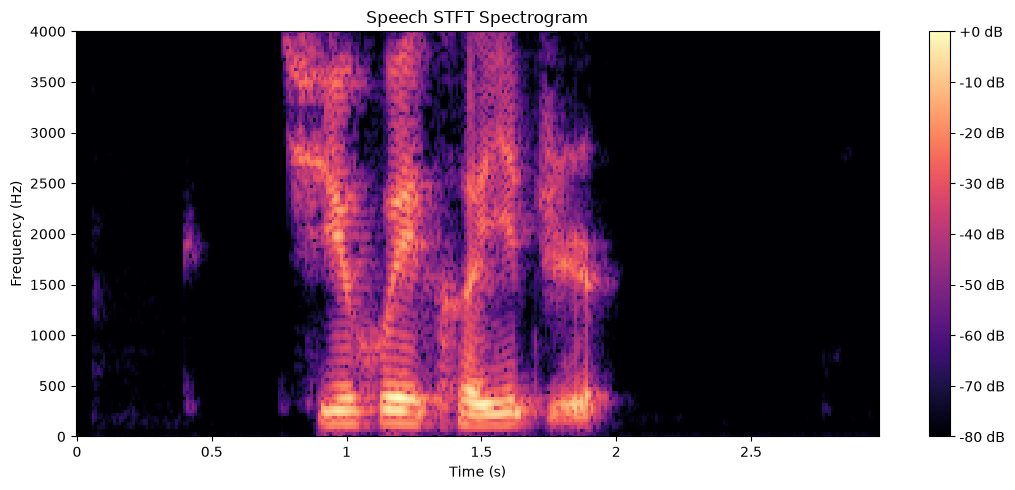

In [5]:
#绘制语谱图
plt.figure(figsize=(11,5))

librosa.display.specshow(
    S_db,
    sr=sr,
    hop_length=hop_length,
    x_axis="time",
    y_axis="linear",
    cmap="magma"
)

plt.ylim(0,4000)
plt.colorbar(format="%+2.0f dB")

plt.title("Speech STFT Spectrogram")
plt.xlabel("Time (s)")
plt.ylabel("Frequency (Hz)")
plt.tight_layout()
plt.show()

win_length=400, duration=0.025s, grid_spacing=0.9766Hz
win_length=1600, duration=0.100s, grid_spacing=0.9766Hz


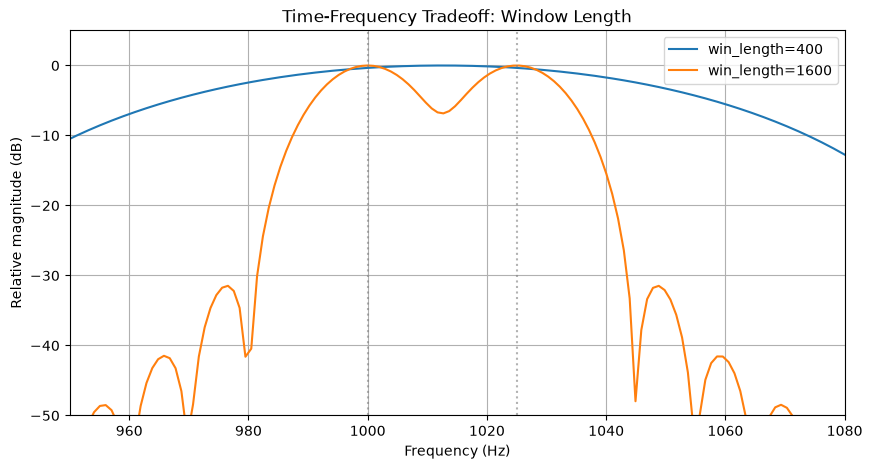

In [2]:
#W5D3实验1
import numpy as np
import matplotlib.pyplot as plt

sr = 16000
f1 = 1000
f2 = 1025

n_fft = 16384
win_lengths = [400,1600]

plt.figure(figsize=(10,5))

for win_length in win_lengths:
    #1.生成对应窗长的真实采样信号
    t = np.arange(win_length) / sr

    x = (
        np.sin(2*np.pi*f1*t) +
        np.sin(2*np.pi*f2*t)
    )

    #2.加Hann窗
    window = np.hanning(win_length)
    x_win = x * window

    #3.进行nfft点rFFT
    X = np.fft.rfft(x_win,n=n_fft)
    freqs = np.fft.rfftfreq(n_fft,d=1/sr)

    #4.计算相对dB幅度谱
    mag = np.abs(X)
    mag = mag / mag.max()

    db = 20 * np.log10(mag + 1e-12)

    #5.绘制频谱
    plt.plot(
        freqs,
        db,
        label=f"win_length={win_length}"
    )

    print(
        f"win_length={win_length}, "
        f"duration={win_length/sr:.3f}s, "
        f"grid_spacing={sr/n_fft:.4f}Hz"
    )

plt.axvline(1000, color="gray", linestyle=":", alpha=0.6)
plt.axvline(1025, color="gray", linestyle=":", alpha=0.6)

plt.xlim(950, 1080)
plt.ylim(-50, 5)

plt.xlabel("Frequency (Hz)")
plt.ylabel("Relative magnitude (dB)")
plt.title("Time-Frequency Tradeoff: Window Length")
plt.legend()
plt.grid(True)
plt.show()

n_fft=1024,freq_bins=513,grid_spacing=15.625000Hz,duration=0.025s
n_fft=16384,freq_bins=8193,grid_spacing=0.976562Hz,duration=0.025s


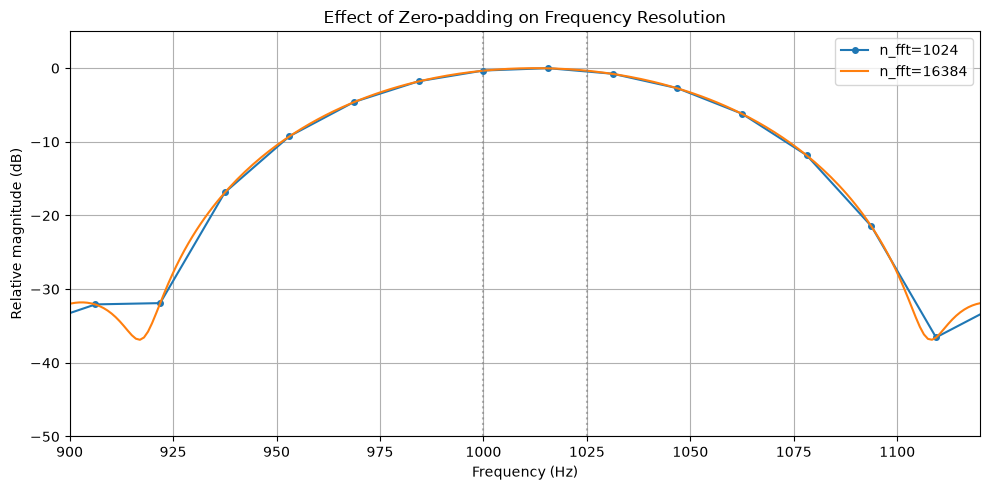

In [5]:
#W5D3实验2
import numpy as np
import matplotlib.pyplot as plt

sr = 16000
f1 = 1000
f2 = 1025

win_length = 400
n_fft_list = [1024,16384]

t = np.arange(win_length) / sr

x = (
    np.sin(2*np.pi*f1*t) +
    np.sin(2*np.pi*f2*t)
)

window = np.hanning(win_length)
x_win = x * window

plt.figure(figsize=(10,5))

for n_fft in n_fft_list:
    X = np.fft.rfft(x_win,n=n_fft)
    freqs = np.fft.rfftfreq(n_fft,d=1/sr)

    mag = np.abs(X)
    mag = mag / mag.max()

    db = 20 * np.log10(mag + 1e-12)

    print(
        f"n_fft={n_fft},"
        f"freq_bins={len(freqs)},"
        f"grid_spacing={sr/n_fft:.6f}Hz,"
        f"duration={win_length/sr:.3f}s"
    )

    if n_fft == 1024:
        plt.plot(
            freqs,
            db,
            "o-",
            markersize=4,
            label=f"n_fft={n_fft}"
        )
    else:
        plt.plot(
            freqs,
            db,
            label=f"n_fft={n_fft}"
        )

#标出真实频率
plt.axvline(1000,color="gray",linestyle=":",alpha=0.6)
plt.axvline(1025,color="gray",linestyle=":",alpha=0.6)

plt.xlim(900, 1120)
plt.ylim(-50, 5)

plt.xlabel("Frequency (Hz)")
plt.ylabel("Relative magnitude (dB)")
plt.title("Effect of Zero-padding on Frequency Resolution")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

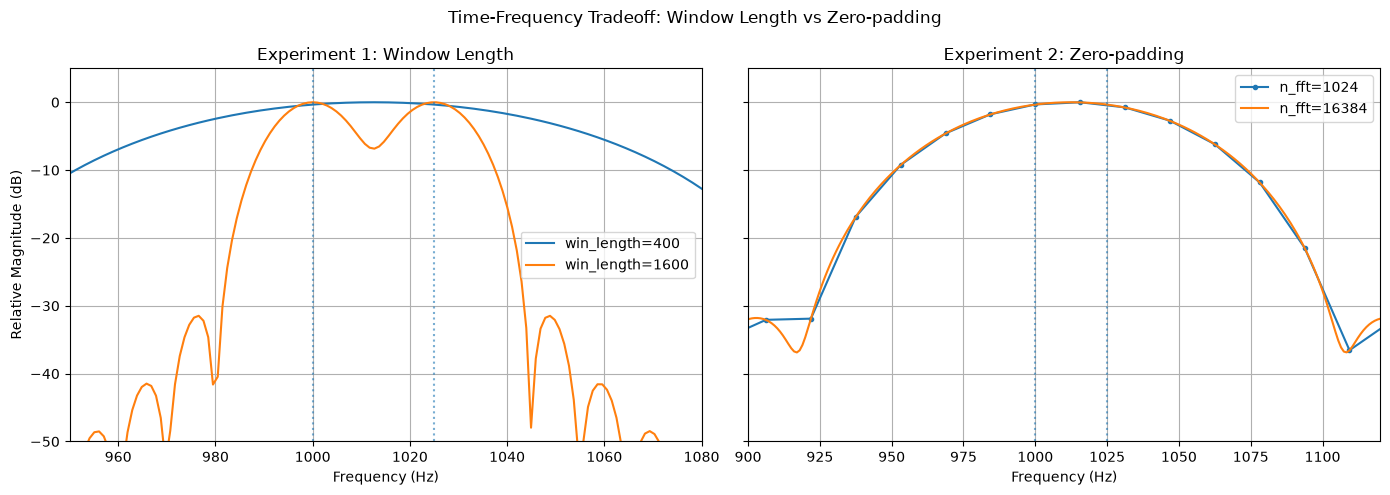

项目根目录: d:\Projects\speech-ai-learning
CSV路径: d:\Projects\speech-ai-learning\results\w05_timefreq.csv
图像路径: d:\Projects\speech-ai-learning\results\w05_timefreq_comparison.png
实验记录数: 4

四组实验记录：
short_window | duration = 25.0 ms | grid = 0.9766 Hz | resolved = no
long_window | duration = 100.0 ms | grid = 0.9766 Hz | resolved = yes
coarse_grid | duration = 25.0 ms | grid = 15.625 Hz | resolved = no
dense_grid | duration = 25.0 ms | grid = 0.9766 Hz | resolved = no


In [7]:
#W5D3整理实验结果
from pathlib import Path
import csv

import numpy as np
import matplotlib.pyplot as plt

#1.定位项目根目录
cwd = Path.cwd()

if (cwd / "src").is_dir() and (cwd / "notebooks").is_dir():
    project_root = cwd
elif (
    (cwd.parent / "src").is_dir()
    and (cwd.parent / "notebooks").is_dir()
):
    project_root = cwd.parent
else:
    project_root = cwd

results_dir = project_root / "results"
results_dir.mkdir(parents=True,exist_ok=True)

csv_path = results_dir / "w05_timefreq.csv"
figure_path = results_dir / "w05_timefreq_comparison.png"

# 2. 固定实验信号
sr = 16000
f1 = 1000
f2 = 1025

tone_gap = f2 - f1

#3.定义频谱计算函数
def compute_spectrum(win_length, n_fft):
    t = np.arange(win_length) / sr

    x = (
        np.sin(2 * np.pi * f1 * t)
        + np.sin(2 * np.pi * f2 * t)
    )

    window = np.hanning(win_length)
    x_win = x * window

    X = np.fft.rfft(x_win, n=n_fft)
    freqs = np.fft.rfftfreq(n_fft,d=1/sr)

    mag = np.abs(X)
    mag = mag / mag.max()

    db = 20*np.log10(mag + 1e-12)

    return freqs, db

#4. 绘制两组对照试验
fig, axes = plt.subplots(
    1,2,
    figsize=(14,5),
    sharey=True
)

#实验A：固定n_fft,改变win_length
for win_length in [400,1600]:
    freqs,db = compute_spectrum(win_length,16384)
    axes[0].plot(
        freqs,
        db,
        label=f"win_length={win_length}"
    )
axes[0].set_xlim(950, 1080)
axes[0].set_ylim(-50, 5)
axes[0].set_title("Experiment 1: Window Length")
axes[0].set_xlabel("Frequency (Hz)")
axes[0].set_ylabel("Relative Magnitude (dB)")
axes[0].legend()
axes[0].grid(True)

for f in [f1,f2]:
    axes[0].axvline(f, linestyle=":", alpha=0.6)

#实验B：固定win_length，改变n_fft
for n_fft in [1024,16384]:
    freqs, db = compute_spectrum(400,n_fft)
    axes[1].plot(
        freqs,
        db,
        marker="o" if n_fft == 1024 else None,
        markersize=3,
        label=f"n_fft={n_fft}"
    )

axes[1].set_xlim(900, 1120)
axes[1].set_ylim(-50, 5)
axes[1].set_title("Experiment 2: Zero-padding")
axes[1].set_xlabel("Frequency (Hz)")
axes[1].legend()
axes[1].grid(True)

for f in [f1, f2]:
    axes[1].axvline(f, linestyle=":", alpha=0.6)

fig.suptitle(
    "Time-Frequency Tradeoff: Window Length vs Zero-padding"
)

fig.tight_layout()

fig.savefig(
    figure_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

#5. 整理四组试验记录
conditions = [
    {
        "experiment_group":"win_length",
        "condition":"short_window", 
        "win_length":400,
        "n_fft": 16384,
        "resolved": "no",
        "observation": "宽峰合并，两个频率未清晰分离"
    },
    {
        "experiment_group":"win_length",
        "condition":"long_window", 
        "win_length":1600,
        "n_fft": 16384,
        "resolved": "yes",
        "observation": "出现两个可区分的峰值"
    },
    {
        "experiment_group": "n_fft",
        "condition": "coarse_grid",
        "win_length": 400,
        "n_fft": 1024,
        "resolved": "no",
        "observation": "频率网格较稀疏，两个频率未清晰分离"
    },
    {
        "experiment_group": "n_fft",
        "condition": "dense_grid",
        "win_length": 400,
        "n_fft": 16384,
        "resolved": "no",
        "observation": "频率网格变密，但两个频率仍未清晰分离"
    }
]

fieldnames = [
    "experiment_group",
    "condition",
    "sr_hz",
    "tone1_hz",
    "tone2_hz",
    "tone_gap_hz",
    "window",
    "win_length_samples",
    "observation_duration_ms",
    "n_fft",
    "fft_bins",
    "frequency_grid_spacing_hz",
    "approx_hann_mainlobe_null_to_null_hz",
    "resolved_as_two_peaks",
    "observation"
]

rows = []

for item in conditions:
    win_length = item["win_length"]
    n_fft = item["n_fft"]

    rows.append({
        "experiment_group": item["experiment_group"],
        "condition": item["condition"],
        "sr_hz": sr,
        "tone1_hz": f1,
        "tone2_hz": f2,
        "tone_gap_hz": tone_gap,
        "window": "Hann",
        "win_length_samples": win_length,
        "observation_duration_ms": (
            win_length / sr * 1000
        ),
        "n_fft": n_fft,
        "fft_bins": n_fft // 2 + 1,
        "frequency_grid_spacing_hz": sr / n_fft,
        "approx_hann_mainlobe_null_to_null_hz": (
            4 * sr / win_length
        ),
        "resolved_as_two_peaks": item["resolved"],
        "observation": item["observation"]
    })

#6.写入csv
with csv_path.open(
    "w",
    newline="",
    encoding="utf-8-sig"
) as f:
    writer = csv.DictWriter(
        f,
        fieldnames=fieldnames
    )

    writer.writeheader()
    writer.writerows(rows)

#7.打印验收信息
print("项目根目录:", project_root)
print("CSV路径:", csv_path)
print("图像路径:", figure_path)
print("实验记录数:", len(rows))

print("\n四组实验记录：")
for row in rows:
    print(
        row["condition"],
        "| duration =", round(
            row["observation_duration_ms"], 2
        ), "ms",
        "| grid =", round(
            row["frequency_grid_spacing_hz"], 4
        ), "Hz",
        "| resolved =", row["resolved_as_two_peaks"]
    )

features.py 导入成功: D:\Projects\speech-ai-learning\src\features.py
noise_utils.py 导入成功: D:\Projects\speech-ai-learning\src\noise_utils.py
parent_uid: common_voice_zh-CN_27897382
split: train
采样率: 32000
波形形状: (202752,)
音频时长: 6.336 秒


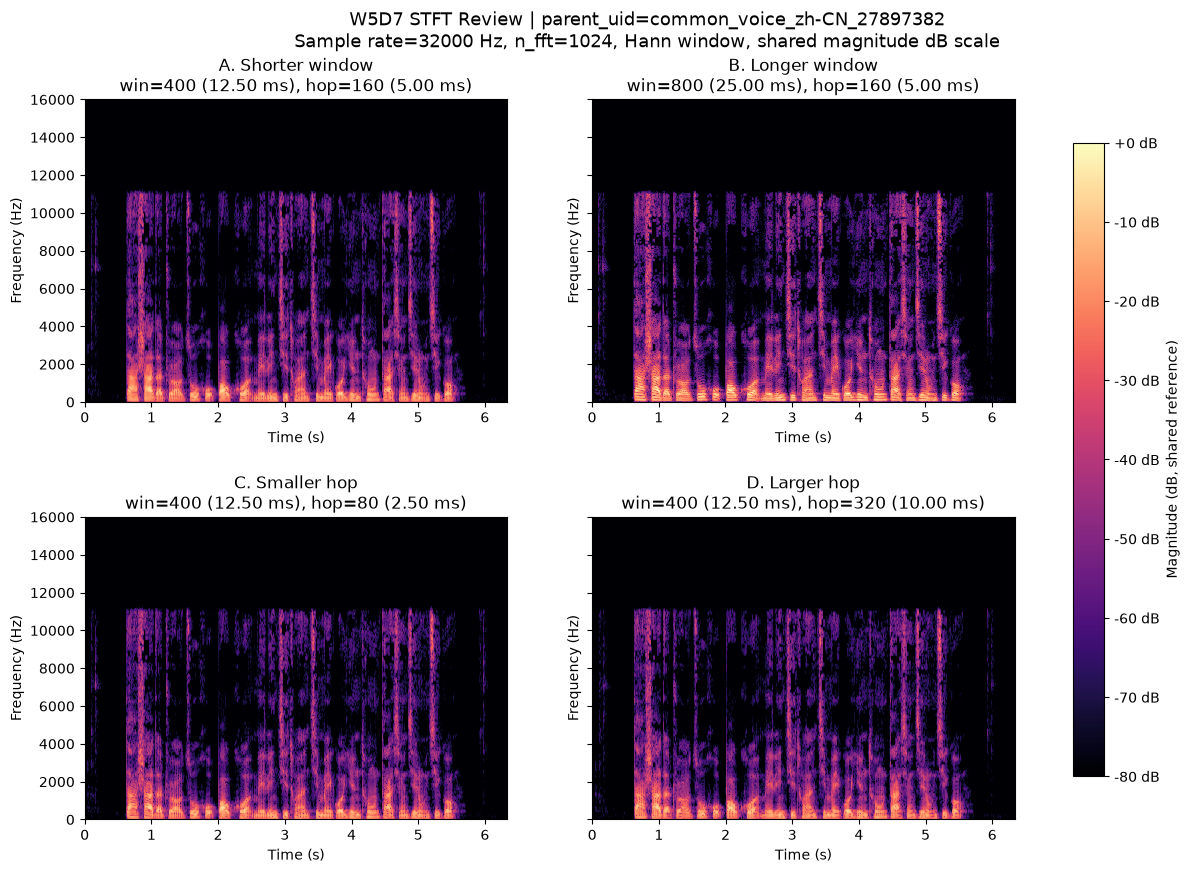


已保存核心图: D:\Projects\speech-ai-learning\results\w05_stft_review.png
manifest.csv 与 test_candidates.csv 哈希检查通过
A. Shorter window | win_length = 400 | hop_length = 160 | STFT shape = (513, 1268)
B. Longer window | win_length = 800 | hop_length = 160 | STFT shape = (513, 1268)
C. Smaller hop | win_length = 400 | hop_length = 80 | STFT shape = (513, 2535)
D. Larger hop | win_length = 400 | hop_length = 320 | STFT shape = (513, 634)


In [8]:
#生成核心语谱图，比较win_length与hop_length的影响
from pathlib import Path
import hashlib
import importlib

import numpy as np
import pandas as pd
import soundfile as sf
import librosa
import librosa.display
import matplotlib.pyplot as plt
import sys

#1.确定项目根目录
root = Path.cwd().resolve()
if root.name.lower() == "notebooks":
    root = root.parent

manifest_path = root / "metadata" / "manifest.csv"
candidates_path = root / "metadata" / "test_candidates.csv"

audio_root = (
    root / "data" / "raw"
    / "common_voice_beijing26"
    / "zh-CN-beijing"
)

output_path = root / "results" / "w05_stft_review.png"

#防止覆盖已有结果
if output_path.exists():
    raise FileExistsError(
        f"{output_path}已存在，请先检查已有图片，勿直接覆盖。"
    )

#2. 记录输入文件哈希，确认本单元不会直接修改原始数据
def sha256_file(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

for p in [manifest_path, candidates_path]:
    if not p.is_file():
        raise FileNotFoundError(f"找不到文件：{p}")

original_hashes = {
    str(p): sha256_file(p)
    for p in [manifest_path, candidates_path]
}

#3.检查已有模块能否直接导入
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

importlib.invalidate_caches()

features_module = importlib.import_module("src.features")
noise_module = importlib.import_module("src.noise_utils")

print("features.py 导入成功:", features_module.__file__)
print("noise_utils.py 导入成功:", noise_module.__file__)

#4.从manifest选择之前用过的train音频
manifest = pd.read_csv(
    manifest_path,
    dtype={"parent_uid":str, "split": str}
)

parent_uid = "common_voice_zh-CN_27897382"

matches = manifest[
    manifest["parent_uid"].eq(parent_uid)
    & manifest["split"].eq("train")
]

if len(matches) != 1:
    raise ValueError(
        f"预期找到1条train音频，实际找到{len(matches)}条。"
        "请检查parent_uid和manifest。"
    )

row = matches.iloc[0]
audio_value = Path(str(row["audio_path"]))

#5.兼容manifest中的相对路径写法
if audio_value.is_absolute():
    candidates = [audio_value]
else:
    candidates = [
        root / audio_value,
        audio_root / audio_value,
        audio_root / "clips" / audio_value.name,
        audio_root / audio_value.name
    ]

audio_path = next(
    (p for p in candidates if p.is_file()),
    None
)

if audio_path is None:
    raise FileNotFoundError(
        f"找不到原始音频：{row['audio_path']}"
    )

#6.读取原始音频并转换为单声道
audio, sr = sf.read(
    audio_path,
    dtype="float32",
    always_2d=True
)

clean = audio.mean(axis=1,dtype=np.float64)

if clean.size == 0 or not np.isfinite(clean).all():
    raise ValueError("音频为空或包含非有限数值")

print("parent_uid:",row["parent_uid"])
print("split:",row["split"])
print("采样率:", sr)
print("波形形状:", clean.shape)
print("音频时长:", round(len(clean) / sr, 3), "秒")

#7.定义四组实验
n_fft = 1024

experiments = [
    {
        "title":"A. Shorter window",
        "win_length": 400,
        "hop_length": 160,
        "group": "Window comparison"
    },
    {
        "title":"B. Longer window",
        "win_length": 800,
        "hop_length": 160,
        "group": "Window comparison"
    },
    {
        "title": "C. Smaller hop",
        "win_length": 400,
        "hop_length": 80,
        "group": "Hop comparison"
    },
    {
        "title": "D. Larger hop",
        "win_length": 400,
        "hop_length": 320,
        "group": "Hop comparison"
    },
]

#8.计算四组STFT
spectrograms = []

for exp in experiments:
    D = librosa.stft(
        y=clean,
        n_fft=n_fft,
        hop_length=exp["hop_length"],
        win_length=exp["win_length"],
        window="hann",
        center="True"
    )

    mag = np.abs(D)

    spectrograms.append({
        **exp,
        "D": D,
        "mag": mag
    })

#9.使用统一的dB参考值，确保四张图可以比较
global_ref = max(
    item["mag"].max()
    for item in spectrograms
)

if global_ref <= 0:
    raise ValueError("输入音频没有有效的频谱幅度")

for item in spectrograms:
    item["db"] = librosa.amplitude_to_db(
        item["mag"],
        ref=global_ref,
        top_db=80
    )

#10.绘制四子图
fig, axes = plt.subplots(
    2,2,
    figsize=(15,9),
    sharey=True
)

for ax, item in zip(axes.ravel(), spectrograms):
    img = librosa.display.specshow(
        item["db"],
        sr=sr,
        hop_length=item["hop_length"],
        n_fft=n_fft,
        x_axis="time",
        y_axis="linear",
        ax=ax,
        vmin=-80,
        vmax=0
    )

    win_ms = item["win_length"] / sr * 1000
    hop_ms = item["hop_length"] / sr * 1000

    ax.set_title(
        f"{item['title']}\n"
        f"win={item['win_length']} ({win_ms:.2f} ms), "
        f"hop={item['hop_length']} ({hop_ms:.2f} ms)"
    )

    ax.set_ylim(0, sr / 2)
    ax.set_xlabel("Time (s)")
    ax.set_ylabel("Frequency (Hz)")

fig.suptitle(
    f"W5D7 STFT Review | parent_uid={parent_uid}\n"
    f"Sample rate={sr} Hz, n_fft={n_fft}, Hann window, "
    "shared magnitude dB scale",
    fontsize=13
)

fig.subplots_adjust(
    hspace=0.38,
    top=0.88,
    bottom=0.08
)

fig.colorbar(
    img,
    ax=axes.ravel().tolist(),
    format="%+2.0f dB",
    label="Magnitude (dB, shared reference)",
    shrink=0.88
)

fig.savefig(
    output_path,
    dpi=180,
    bbox_inches="tight"
)

plt.show()

print("\n已保存核心图:", output_path)

#11.检查原始元数据文件是否被本实验修改
current_hashes = {
    str(p): sha256_file(p)
    for p in [manifest_path, candidates_path]
}

assert current_hashes == original_hashes

print("manifest.csv 与 test_candidates.csv 哈希检查通过")

# 12. 输出各实验的STFT形状，辅助理解帧数变化
for item in spectrograms:
    print(
        item["title"],
        "| win_length =", item["win_length"],
        "| hop_length =", item["hop_length"],
        "| STFT shape =", item["D"].shape
    )